# AISE 4010 Course Project: Group 1

**Stage 2 (Lab 9): Recurrent Models, TCN and Grid Search**

Lab section 3. Dataset 4 in the verified pool (Open Power System Data).

Day-ahead forecasting of Germany's hourly electricity load. The notebook follows the order and code of the Lab 6 tutorial, with two project settings in place of the tutorial's: the window reads 168 hours instead of 24, and the output is the next 24 hours instead of the next hour.

| Requirement | Section |
|---|---|
| Source, target, unit, frequency, coverage, gaps, duplicates, missingness | 1, 2 |
| Exploratory figures | 3, 4 |
| Chronological split, imputer, scaler, window shapes | 2, 3, 5 |
| Traditional baselines | 6 |
| MLP, CNN, RNN, LSTM, GRU and TCN under one protocol, with parameters, training and inference time and baseline improvement | 7 |
| Grid search space, budget, objective and stopping rule, then the trials | 8 |
| Final model selected on validation, with checkpoint | 9 |
| Smoke test | 10 |
| Conclusion and unresolved risk | 11 |

Run the cells top to bottom in a fresh kernel (about an hour on a laptop CPU). A GPU is not needed.

**Changes since Stage 1.** The pipeline now follows Lab 6 and every model was retrained, so the Stage 1 results stay in the Stage 1 checkpoint. The inputs are load plus plain hour and weekday columns instead of sine/cosine channels. Scaling, windows and training settings come from Lab 6, and models are scored with their best-epoch weights instead of a refit on train + validation. Stage 2 selects on validation only, so the test set is not used in this notebook.

## Settings

Run first. The seed is recorded here and reset before each training run, as in Lab 6.

In [1]:
import json
import os
import time
import urllib.request
from itertools import product

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")  # hides a harmless tf.data notice that TF 2.20 logs on every fit

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.linear_model import Ridge
from tensorflow import keras
from tensorflow.keras import layers

SEED = 4010
keras.utils.set_random_seed(SEED)

plt.rcParams.update({
    "font.family": ["Arial", "DejaVu Sans"],
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e6e6",
    "legend.frameon": False,
    "figure.dpi": 110,
})
BLACK, GREY, LIGHT, ACCENT = "#000000", "#7a7a7a", "#c4c4c4", "#1f5aa6"

print("TensorFlow", tf.__version__, "| NumPy", np.__version__, "| seed", SEED,
      "| devices", [d.device_type for d in tf.config.list_physical_devices()])

TensorFlow 2.20.0 | NumPy 2.5.3 | seed 4010 | devices ['CPU']


## 1. Problem Definition

| Item | Choice |
|---|---|
| Dataset | OPSD Time series package, version 2020-10-06, file `time_series_60min_singleindex.csv` |
| Target | `DE_load_actual_entsoe_transparency`: total electricity load of Germany reported to ENTSO-E |
| Unit | MW (hourly average) |
| Native frequency | 1 hour, UTC timestamps |
| Resampling rule | None; the series is already on a complete hourly grid (audit in Section 2) |
| Lookback | 168 h (one week), justified by the autocorrelation in Section 4 |
| Horizon | Next 24 h, predicted in one shot (direct multi-output forecast, one output per hour) |
| Inputs | Past 168 h of load, hour of day and day of week (calendar values are known in advance) |
| Split | Chronological 60 / 20 / 20 (train / validation / test), never shuffled across time |
| Metrics | MAE and RMSE in MW, plus improvement over the best traditional baseline |
| Selection metric | Validation RMSE (MW) |

**Operational interpretation.** Every hour the model issues a forecast of national load for the next 24 hours. Grid operators and market participants use forecasts like this to schedule generation and buy balancing reserves, so an error of 1,000 MW is roughly the output of one large power plant that was planned but not needed (or missing).

## 2. The Data

The raw OPSD file (about 124 MB) is downloaded once into `data/` and is not committed to GitHub. Only the timestamp and target columns are read.

**Table 1.** Data audit of the target series.

In [2]:
DATA_FILE = "data/time_series_60min_singleindex.csv"
DATA_URL = "https://data.open-power-system-data.org/time_series/2020-10-06/time_series_60min_singleindex.csv"
TARGET = "DE_load_actual_entsoe_transparency"

os.makedirs("data", exist_ok=True)
if not os.path.exists(DATA_FILE):
    urllib.request.urlretrieve(DATA_URL, DATA_FILE)

df = pd.read_csv(DATA_FILE, usecols=["utc_timestamp", TARGET], parse_dates=["utc_timestamp"])
series = df.set_index("utc_timestamp")[TARGET].rename("load_MW")
series = series.loc[series.first_valid_index():series.last_valid_index()]  # the file runs past the target's coverage

display(pd.Series({
    "First timestamp (UTC)": series.index[0],
    "Last timestamp (UTC)": series.index[-1],
    "Rows": len(series),
    "Expected hourly rows": len(pd.date_range(series.index[0], series.index[-1], freq="h")),
    "Duplicated timestamps": series.index.duplicated().sum(),
    "Steps other than 1 h": (series.index.to_series().diff().dropna().dt.total_seconds() != 3600).sum(),
    "Missing values": series.isna().sum(),
}, name="value").to_frame())

series = series.asfreq("h").ffill()  # Lab 6 cleaning; a forward fill only copies an earlier value, so it cannot leak

,value
First timestamp (UTC),2015-01-01 00:00:00+00:00
Last timestamp (UTC),2020-09-30 23:00:00+00:00
Rows,50400
Expected hourly rows,50400
Duplicated timestamps,0
Steps other than 1 h,0
Missing values,0


The target covers 1 January 2015 to 30 September 2020 on a complete hourly UTC grid with no duplicates, gaps or missing values, so no resampling is needed and the imputer (the forward fill in the last line) changes nothing. OPSD had already filled gaps of up to 2 hours by linear interpolation before publishing, so "0 missing" describes the published file. Timestamps stay in UTC, which avoids the repeated and skipped hours of daylight-saving time.

OPSD takes this column from the ENTSO-E Transparency Platform, where total load is generation, minus the power plants' own consumption, plus imports, minus exports, minus consumption by storage. The 60-minute file holds hourly averages.

## 3. Chronological Split

The series is split 60 / 20 / 20 in time order before scaling and windowing, so no statistic from the validation or test period can reach training. The test rows are only counted here; their load values are not used anywhere in this notebook.

**Table 2.** Chronological split of the hourly series.

In [3]:
n = len(series)
train_end, val_end = int(0.60 * n), int(0.80 * n)

parts = {"train": series.index[:train_end], "validation": series.index[train_end:val_end], "test": series.index[val_end:]}
display(pd.DataFrame({
    "start (UTC)": [part[0] for part in parts.values()],
    "end (UTC)": [part[-1] for part in parts.values()],
    "hours": [len(part) for part in parts.values()],
    "share (%)": [round(100 * len(part) / n, 1) for part in parts.values()],
}, index=list(parts)))

,start (UTC),end (UTC),hours,share (%)
train,2015-01-01 00:00:00+00:00,2018-06-13 23:00:00+00:00,30240,60.0
validation,2018-06-14 00:00:00+00:00,2019-08-07 23:00:00+00:00,10080,20.0
test,2019-08-08 00:00:00+00:00,2020-09-30 23:00:00+00:00,10080,20.0


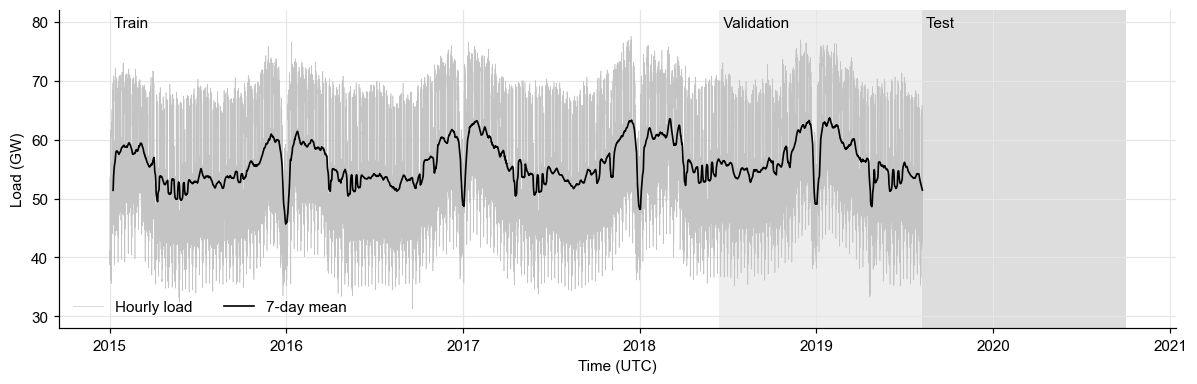

In [4]:
seen = series.iloc[:val_end]  # the test band stays empty so no test value is shown

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(seen.index, seen / 1000, color=LIGHT, linewidth=0.4, label="Hourly load")
ax.plot(seen.index, seen.rolling(24 * 7).mean() / 1000, color=BLACK, linewidth=1.1, label="7-day mean")
ax.axvspan(parts["validation"][0], parts["validation"][-1], color=GREY, alpha=0.12, linewidth=0)
ax.axvspan(parts["test"][0], parts["test"][-1], color=GREY, alpha=0.25, linewidth=0)
for name, part in parts.items():
    ax.text(part[0], 81, f" {name.capitalize()}", va="top")
ax.set_ylim(28, 82)
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Load (GW)")
ax.legend(loc="lower left", ncol=2)
plt.tight_layout()
plt.show()

**Fig. 1.** Hourly German load over the training and validation periods, with its 7-day mean. The light band marks validation; the dark band marks the test period, whose values are not drawn.

Load follows a yearly cycle: the 7-day mean sits around 52–54 GW in summer and 60–63 GW in winter, with a sharp dip over Christmas and New Year every year.

## 4. Exploratory Analysis on the Training Split

The lookback is chosen from the training split only, so the validation and test periods cannot influence it.

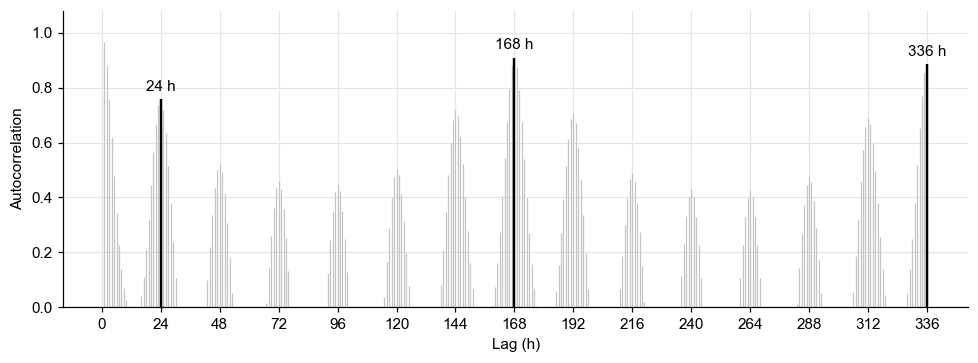

ACF at 24 h: 0.758 | 72 h: 0.46 | 168 h: 0.91 | 336 h: 0.885


In [5]:
train = series.iloc[:train_end]
lags = np.arange(1, 24 * 14 + 1)
acf = np.array([train.autocorr(lag) for lag in lags])

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.vlines(lags, 0, acf, color=LIGHT, linewidth=0.8)
for lag in (24, 168, 336):
    ax.vlines(lag, 0, acf[lag - 1], color=BLACK, linewidth=1.6)
    ax.text(lag, acf[lag - 1] + 0.03, f"{lag} h", ha="center")
ax.set_xticks(range(0, 24 * 14 + 1, 24))
ax.set_ylim(0, 1.08)
ax.set_xlabel("Lag (h)")
ax.set_ylabel("Autocorrelation")
plt.tight_layout()
plt.show()

print("ACF at 24 h:", round(acf[23], 3), "| 72 h:", round(acf[71], 3),
      "| 168 h:", round(acf[167], 3), "| 336 h:", round(acf[335], 3))

**Fig. 2.** Autocorrelation of hourly training load for lags up to two weeks; the 24 h, 168 h and 336 h lags are highlighted.

The autocorrelation peaks every 24 h, and the weekly peaks are the strongest: 0.91 at 168 h and 0.885 at 336 h, against 0.758 at 24 h, because the same hour one week earlier falls on the same type of day while yesterday may be a weekend. A 168 h lookback therefore contains both the previous day and the same hour last week; a two-week lookback adds little, since the 336 h peak is lower than the 168 h one.

A 168 h window shows the daily and weekly cycle in the load itself, and the hour and weekday columns state the position in those cycles directly. Both are known in advance for any hour, so they cannot leak.

## 5. Samples for Supervised Learning

As in Lab 6 A2, the load is standardized with the mean and standard deviation of the training part only, and `make_windows` cuts the inputs into `[samples, timesteps, features]`. As in Lab 6 A6, the calendar is added as extra input series, here as plain numbers scaled to 0–1: hour of day divided by 23 and day of week divided by 6. Each sample reads the previous `WINDOW` hours and its target is the next `HORIZON` hours of load. A forecast is issued every hour, so consecutive windows overlap by 167 hours. The same arrays feed every model.

**Table 3.** Window shapes per split.

In [6]:
WINDOW, HORIZON = 168, 24

values = series.values[:val_end].astype("float32")               # stops at the last validation row
mean, std = values[:train_end].mean(), values[:train_end].std()  # training statistics only
load = (values - mean) / std
inputs = np.column_stack([load, series.index[:val_end].hour / 23, series.index[:val_end].dayofweek / 6]).astype("float32")

def make_windows(data, start, end):
    """One sample per forecast start t in [start, end): input = the WINDOW hours before t, target = the HORIZON hours of load from t."""
    targets = np.arange(max(start, WINDOW), end - HORIZON + 1)
    X = np.stack([data[t - WINDOW:t] for t in targets])
    y = np.stack([load[t:t + HORIZON] for t in targets])
    return X, y, targets

X_train, y_train, t_train = make_windows(inputs, 0, train_end)
X_val, y_val, t_val = make_windows(inputs, train_end, val_end)

display(pd.DataFrame({
    "X (samples, timesteps, features)": [str(X_train.shape), str(X_val.shape), f"({n - val_end - HORIZON + 1}, {WINDOW}, {inputs.shape[1]})"],
    "y (samples, horizon)": [str(y_train.shape), str(y_val.shape), f"({n - val_end - HORIZON + 1}, {HORIZON})"],
}, index=["train", "validation", "test (built in Stage 3)"]))

print("Scaling (training only): mean", round(float(mean), 1), "MW, std", round(float(std), 1), "MW")
t = t_val[0]
print("First validation input :", series.index[t - WINDOW], "to", series.index[t - 1])
print("First validation target:", series.index[t], "to", series.index[t + HORIZON - 1])
print("Last validation target ends:", series.index[t_val[-1] + HORIZON - 1], "| test starts:", series.index[val_end])

,"X (samples, timesteps, features)","y (samples, horizon)"
train,"(30049, 168, 3)","(30049, 24)"
validation,"(10057, 168, 3)","(10057, 24)"
test (built in Stage 3),"(10057, 168, 3)","(10057, 24)"


Scaling (training only): mean 55740.7 MW, std 10063.4 MW
First validation input : 2018-06-07 00:00:00+00:00 to 2018-06-13 23:00:00+00:00
First validation target: 2018-06-14 00:00:00+00:00 to 2018-06-14 23:00:00+00:00
Last validation target ends: 2019-08-07 23:00:00+00:00 | test starts: 2019-08-08 00:00:00+00:00


**Leakage controls**

- The mean and standard deviation come from the training split only.
- The imputer is a forward fill, which only copies earlier values, and it found nothing to fill.
- The hour and weekday columns are fixed by the timestamp and known in advance.
- Every target hour lies inside its own split and comes after every input hour of its window. A validation window may read training hours as inputs, because those hours are already observed when the forecast is issued (Lab 6 A2).
- The arrays stop at the last validation row, so test values cannot enter any window.

## 6. Traditional Baselines

Every model is scored in MW after the scaling is undone, over every forecast hour of every validation window. Validation RMSE is the selection metric because large misses are the costliest for grid operation. Improvement is reported against the best traditional baseline.

Four non-neural baselines use exactly the same windows and targets:

- **Persistence**: repeat the last observed hour for all 24 steps (the naive forecast of Lab 3 and Lab 6).
- **Seasonal naive 24 h**: each hour equals the same hour yesterday.
- **Seasonal naive 168 h**: each hour equals the same hour one week earlier.
- **Linear AR (ridge)**: a direct multi-output linear regression on the flattened window, i.e. the autoregressive part of an ARIMA model (Lecture 2) fitted by least squares. A small ridge penalty keeps the fit stable because neighbouring lags and the calendar columns are strongly correlated.

**Table 4.** Validation scores of the traditional baselines.

In [7]:
def to_mw(z):
    return z * std + mean

def flat(X):
    return X.reshape(len(X), -1).astype("float64")  # the calendar columns are nearly collinear, too much for a float32 solve

actual = to_mw(y_val)
forecasts = {
    "Persistence": to_mw(np.repeat(X_val[:, -1:, 0], HORIZON, axis=1)),
    "Seasonal naive 24 h": to_mw(X_val[:, -24:, 0]),       # target hour t+h is copied from t+h-24
    "Seasonal naive 168 h": to_mw(X_val[:, :HORIZON, 0]),  # target hour t+h is copied from t+h-168
}
parameters, train_time, infer_time = {}, {}, {}

start = time.time()
ridge = Ridge(alpha=1.0).fit(flat(X_train), y_train)
train_time["Linear AR (ridge)"] = time.time() - start
start = time.time()
forecasts["Linear AR (ridge)"] = to_mw(ridge.predict(flat(X_val)))
infer_time["Linear AR (ridge)"] = 1000 * (time.time() - start) / len(X_val)
parameters["Linear AR (ridge)"] = ridge.coef_.size + ridge.intercept_.size

def mae(name):
    return np.mean(np.abs(forecasts[name] - actual))

def rmse(name):
    return np.sqrt(np.mean((forecasts[name] - actual) ** 2))

baselines = list(forecasts)
best_baseline = min(baselines, key=rmse)

def compare(names):
    table = pd.DataFrame({name: {
        "MAE (MW)": mae(name),
        "RMSE (MW)": rmse(name),
        "MAE gain (%)": 100 * (1 - mae(name) / mae(best_baseline)),
        "RMSE gain (%)": 100 * (1 - rmse(name) / rmse(best_baseline)),
        "parameters": parameters.get(name, 0),
        "training time (s)": train_time.get(name, 0),
        "inference (ms / window)": infer_time.get(name, 0),
    } for name in names}).T.sort_values(["RMSE (MW)", "parameters"])
    table["parameters"] = table["parameters"].astype(int)
    return table.round({"MAE (MW)": 1, "RMSE (MW)": 1, "MAE gain (%)": 1, "RMSE gain (%)": 1,
                        "training time (s)": 1, "inference (ms / window)": 3})

display(compare(baselines))
print("Best traditional baseline on validation:", best_baseline)

,MAE (MW),RMSE (MW),MAE gain (%),RMSE gain (%),parameters,training time (s),inference (ms / window)
Linear AR (ridge),1240.3,2156.0,0.0,0.0,12120,0.1,0.001
Seasonal naive 168 h,2389.4,4195.8,-92.6,-94.6,0,0.0,0.000
Seasonal naive 24 h,4627.8,7032.0,-273.1,-226.2,0,0.0,0.000
Persistence,8871.0,11221.5,-615.2,-420.5,0,0.0,0.000


Best traditional baseline on validation: Linear AR (ridge)


The weekly seasonal naive (4,196 MW validation RMSE) is far better than the daily one (7,032 MW) and persistence (11,222 MW), as Fig. 2 suggests. The linear AR model is the strongest baseline at 2,156 MW, so it is the reference for the gain columns from here on.

## 7. Neural Models

The models are built as in Lab 6 A3: `make_model` wraps a list of hidden layers with the input and the output layer, and the only change is `Dense(24)` for the 24 forecast hours.

| Model | Hidden layers (followed by `Dense(24)`) | Source |
|---|---|---|
| MLP | `Flatten`, `Dense(128, activation="relu")` | Lab 3 |
| CNN | two blocks of `Conv1D(32, 3, padding="same")` and `MaxPooling1D(2)`, `Flatten`, `Dense(64, activation="relu")` | Lecture 4, Assignment 2 |
| Stacked SimpleRNN | `SimpleRNN(64, return_sequences=True)`, `SimpleRNN(32)` | Lab 6 A3 |
| Stacked LSTM | `LSTM(64, return_sequences=True)`, `LSTM(32)` | Lab 6 A3 |
| Stacked GRU | `GRU(64, return_sequences=True)`, `GRU(32)` | Lab 6 A3 |
| TCN | seven `Conv1D(32, 3, padding="causal")` layers with dilations 1, 2, 4, ..., 64, then the last time step | Bai et al. [4] |

Causal padding means each TCN output only sees current and earlier hours, and the doubling dilations give a receptive field of 1 + 2 × (1 + 2 + ... + 64) = 255 hours, more than the 168 h window. The last time step has therefore seen the whole window, so `Cropping1D` keeps only that step for the output layer.

In [8]:
def make_model(name, hidden_layers, lr=2e-3):
    model = keras.Sequential([keras.Input(shape=(WINDOW, inputs.shape[1]))] + hidden_layers + [layers.Dense(HORIZON)], name=name)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr, clipnorm=1.0), loss="mse")
    return model

keras.utils.set_random_seed(SEED)
models = {
    "MLP": make_model("mlp", [layers.Flatten(), layers.Dense(128, activation="relu")]),
    "CNN": make_model("cnn", [layers.Conv1D(32, 3, activation="relu", padding="same"), layers.MaxPooling1D(2),
                              layers.Conv1D(32, 3, activation="relu", padding="same"), layers.MaxPooling1D(2),
                              layers.Flatten(), layers.Dense(64, activation="relu")]),
    "SimpleRNN": make_model("simplernn", [layers.SimpleRNN(64, return_sequences=True), layers.SimpleRNN(32)]),
    "LSTM": make_model("lstm", [layers.LSTM(64, return_sequences=True), layers.LSTM(32)]),
    "GRU": make_model("gru", [layers.GRU(64, return_sequences=True), layers.GRU(32)]),
    "TCN": make_model("tcn", [layers.Conv1D(32, 3, padding="causal", dilation_rate=d, activation="relu")
                              for d in (1, 2, 4, 8, 16, 32, 64)] + [layers.Cropping1D((WINDOW - 1, 0)), layers.Flatten()]),
}
families = list(models)

### 7.1 Training

All networks get the same budget, as in Lab 6 A4: MSE loss on scaled values, Adam with learning rate 0.002 and gradient clipping (`clipnorm=1.0`), batch size 128, at most 30 epochs, and early stopping on validation loss with patience 6 and the best weights restored. `fit` shuffles the order of the windows between epochs, as in Lab 6. This does not break time order, because the split is already fixed and every window keeps its own past and its own target.

In [9]:
EPOCHS, BATCH_SIZE, PATIENCE = 30, 128, 6
histories = {}

def train(name, model):
    keras.utils.set_random_seed(SEED)
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
    start = time.time()
    history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=EPOCHS, batch_size=BATCH_SIZE,
                        callbacks=[stop], verbose=0)
    train_time[name], histories[name] = time.time() - start, history.history

    model.predict(X_val[:BATCH_SIZE], verbose=0)  # Keras builds its graph on the first call, which is not inference time
    start = time.time()
    forecasts[name] = to_mw(model.predict(X_val, batch_size=BATCH_SIZE, verbose=0))
    infer_time[name] = 1000 * (time.time() - start) / len(X_val)
    parameters[name] = model.count_params()

    best = int(np.argmin(history.history["val_loss"]))
    print(f"{name:32s} {len(history.history['loss']):2d} epochs in {train_time[name]:6.1f} s | best epoch {best + 1:2d}: "
          f"training loss {history.history['loss'][best]:.4f}, validation loss {history.history['val_loss'][best]:.4f}", flush=True)

for name, model in models.items():
    train(name, model)

MLP                              28 epochs in    5.4 s | best epoch 22: training loss 0.0338, validation loss 0.0378


CNN                              17 epochs in   15.1 s | best epoch 11: training loss 0.0308, validation loss 0.0406


SimpleRNN                        16 epochs in  101.5 s | best epoch 10: training loss 0.0495, validation loss 0.0444


LSTM                             26 epochs in  582.2 s | best epoch 20: training loss 0.0343, validation loss 0.0357


GRU                              30 epochs in  646.7 s | best epoch 24: training loss 0.0375, validation loss 0.0366


TCN                              30 epochs in  251.0 s | best epoch 30: training loss 0.0298, validation loss 0.0389


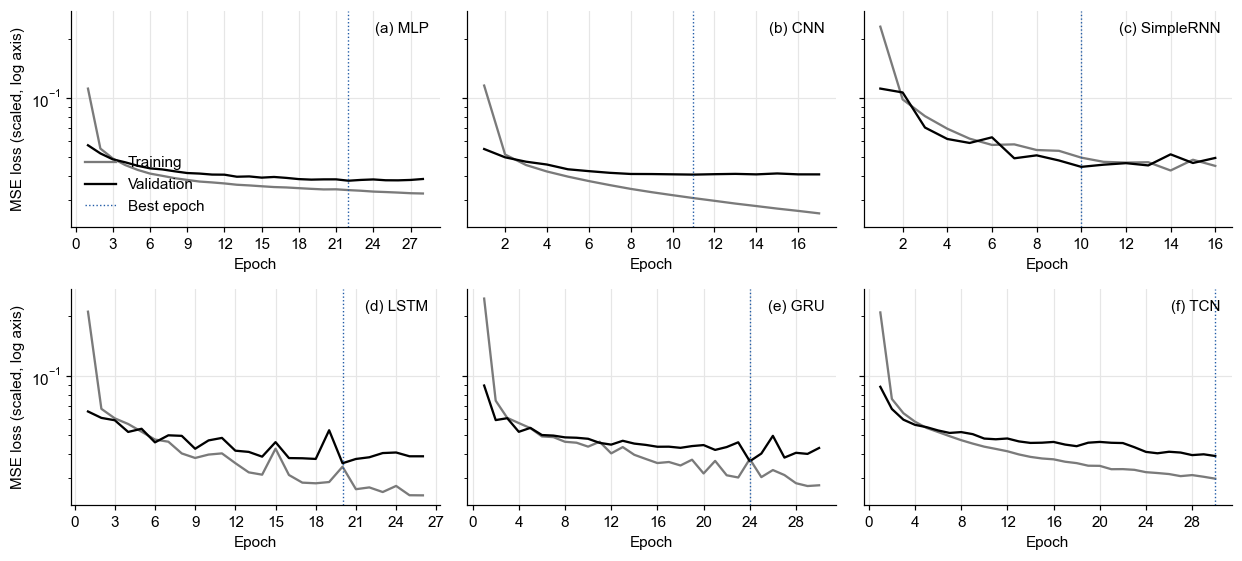

In [10]:
def plot_losses(histories, columns=3):
    rows = -(-len(histories) // columns)
    fig, axes = plt.subplots(rows, columns, figsize=(3.8 * columns, 2.6 * rows), sharey=True, squeeze=False)
    for ax, (name, h), label in zip(axes.flat, histories.items(), "abcdef"):
        epochs = np.arange(1, len(h["loss"]) + 1)
        ax.plot(epochs, h["loss"], color=GREY, label="Training")
        ax.plot(epochs, h["val_loss"], color=BLACK, label="Validation")
        ax.axvline(np.argmin(h["val_loss"]) + 1, color=ACCENT, linewidth=0.9, linestyle=":", label="Best epoch")
        ax.text(0.97, 0.95, f"({label}) {name}", transform=ax.transAxes, ha="right", va="top")
        ax.set_yscale("log")
        ax.set_xlabel("Epoch")
        ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    for ax in axes[:, 0]:
        ax.set_ylabel("MSE loss (scaled, log axis)")
    axes.flat[0].legend(loc="lower left")
    plt.tight_layout()
    plt.show()

plot_losses(histories)

**Fig. 3.** Training and validation loss per epoch; the dotted line marks the epoch with the lowest validation loss, whose weights are kept.

Validation loss falls quickly over the first few epochs and then flattens for every model. The CNN shows the clearest overfitting: training loss keeps falling while validation loss stays flat near 0.041, and early stopping ends the run at epoch 17. The LSTM and GRU curves are noisier, and their training loss drops below validation loss in the second half of training, which is mild overfitting. The SimpleRNN curves stay close together at a higher level (0.050 training, 0.044 validation at its best epoch), which points to underfitting rather than overfitting. The TCN's best epoch is its last, so it was still improving when the 30-epoch budget ended.

### 7.2 Validation Comparison

All models so far, on the validation set. The network with the lowest validation RMSE goes to the grid search.

**Table 5.** Validation comparison of the baselines and the starting networks, best first.

In [11]:
display(compare(baselines + families))
print("Lowest validation RMSE among the networks:", min(families, key=rmse))

,MAE (MW),RMSE (MW),MAE gain (%),RMSE gain (%),parameters,training time (s),inference (ms / window)
LSTM,1225.5,1901.7,1.2,11.8,30616,582.2,0.232
GRU,1268.7,1924.0,-2.3,10.8,23448,646.7,0.171
MLP,1234.0,1955.7,0.5,9.3,67736,5.4,0.006
TCN,1301.4,1984.2,-4.9,8.0,19736,251.0,0.089
CNN,1306.2,2027.1,-5.3,6.0,91064,15.1,0.015
SimpleRNN,1389.2,2121.4,-12.0,1.6,8248,101.5,0.063
Linear AR (ridge),1240.3,2156.0,0.0,0.0,12120,0.1,0.001
Seasonal naive 168 h,2389.4,4195.8,-92.6,-94.6,0,0.0,0.000
Seasonal naive 24 h,4627.8,7032.0,-273.1,-226.2,0,0.0,0.000
Persistence,8871.0,11221.5,-615.2,-420.5,0,0.0,0.000


Lowest validation RMSE among the networks: LSTM


All six networks beat the best baseline on RMSE (1,902 to 2,121 MW against 2,156 MW), but only the LSTM and MLP also beat it on MAE (1,226 and 1,234 MW against 1,240 MW), so most of the networks' gain comes from fewer large misses. The LSTM has the lowest validation RMSE, so it goes to the grid search. The cost differs widely: the LSTM and GRU train in about 10 minutes, the TCN in about 4 minutes, and the CNN and MLP in seconds.

## 8. Grid Search

LSTM has the lowest validation RMSE among the networks in Table 5, so it is the model tuned here. The search is fixed before any trial is shown. The grid is 2 × 2, the same size as the Lab 3 grid, and tunes the same two hyperparameters.

| Item | Choice |
|---|---|
| Model | LSTM |
| Search space | units of the first layer {32, 64}; learning rate {0.002, 0.0005} |
| Budget | 4 configurations |
| Objective | Lowest validation RMSE (MW) |
| Stopping rule per run | Early stopping on validation loss, patience 6, at most 30 epochs, best weights restored |
| Tie-break | Fewer parameters |

**Table 6.** Grid search trials, best first.

In [12]:
def build_lstm(units, lr):
    return make_model(f"lstm_{units}_{lr}", [layers.LSTM(units, return_sequences=True), layers.LSTM(units // 2)], lr=lr)

grid = {"units": [32, 64], "lr": [2e-3, 5e-4]}

trials = []
for units, lr in product(grid["units"], grid["lr"]):
    keras.utils.set_random_seed(SEED)
    name = f"LSTM (units={units}, lr={lr})"
    models[name] = build_lstm(units, lr)
    train(name, models[name])
    trials.append(name)

grid_results = compare(trials)
display(grid_results)
best_trial = grid_results.index[0]
print("Best configuration:", best_trial, f"| grid cost {sum(train_time[name] for name in trials) / 60:.1f} min")

LSTM (units=32, lr=0.002)        27 epochs in  315.6 s | best epoch 21: training loss 0.0370, validation loss 0.0416


LSTM (units=32, lr=0.0005)       30 epochs in  326.9 s | best epoch 30: training loss 0.0443, validation loss 0.0500


LSTM (units=64, lr=0.002)        20 epochs in  636.2 s | best epoch 14: training loss 0.0319, validation loss 0.0396


LSTM (units=64, lr=0.0005)       30 epochs in  698.3 s | best epoch 29: training loss 0.0321, validation loss 0.0442


,MAE (MW),RMSE (MW),MAE gain (%),RMSE gain (%),parameters,training time (s),inference (ms / window)
"LSTM (units=64, lr=0.002)",1298.2,2003.2,-4.7,7.1,30616,636.2,0.236
"LSTM (units=32, lr=0.002)",1388.6,2052.0,-12.0,4.8,8152,315.6,0.118
"LSTM (units=64, lr=0.0005)",1376.7,2115.7,-11.0,1.9,30616,698.3,0.247
"LSTM (units=32, lr=0.0005)",1549.3,2250.9,-24.9,-4.4,8152,326.9,0.112


Best configuration: LSTM (units=64, lr=0.002) | grid cost 33.0 min


The best configuration is 64 units with learning rate 0.002 (2,003 MW), the same settings as the starting LSTM. The lower learning rate is worse at both sizes, although both of those runs reached their best epoch at or near the 30-epoch limit, so the budget may hold them back. The 32-unit model is only 49 MW behind the winner with about a quarter of the parameters and half the training time.

The grid winner and the starting LSTM use the same settings and differ only in their random initial weights, yet they score 2,003 and 1,902 MW. That is a spread of about 100 MW from the seed alone, so the grid found no setting better than the starting one.

## 9. Final Model Selection and Checkpoint

The final model is the network with the lowest validation RMSE, with fewer parameters as the tie-break, so the architecture name plays no part. The selected model, its configuration and the preprocessing state (training mean and standard deviation, split points, window and horizon) are saved to `artifacts/` for the final stage.

**Table 7.** Validation comparison of all models, including the grid winner, best first.

In [13]:
final_table = compare(baselines + families + [best_trial])
display(final_table)
final_name = next(name for name in final_table.index if name in models)

os.makedirs("artifacts", exist_ok=True)
models[final_name].save("artifacts/best_model.keras")
with open("artifacts/final_config.json", "w") as f:
    json.dump({
        "final model": final_name, "grid": grid, "grid winner": best_trial,
        "inputs": ["load (scaled)", "hour / 23", "weekday / 6"], "window": WINDOW, "horizon": HORIZON,
        "train end": train_end, "validation end": val_end, "mean (MW)": float(mean), "std (MW)": float(std),
        "epochs": EPOCHS, "patience": PATIENCE, "batch size": BATCH_SIZE, "seed": SEED,
    }, f, indent=2)
grid_results.to_csv("artifacts/grid_results.csv")
final_table.to_csv("artifacts/validation_comparison.csv")

print("Final model:", final_name, "| beats", best_baseline, "on validation:", rmse(final_name) < rmse(best_baseline))
print("Files:", sorted(os.listdir("artifacts")))

,MAE (MW),RMSE (MW),MAE gain (%),RMSE gain (%),parameters,training time (s),inference (ms / window)
LSTM,1225.5,1901.7,1.2,11.8,30616,582.2,0.232
GRU,1268.7,1924.0,-2.3,10.8,23448,646.7,0.171
MLP,1234.0,1955.7,0.5,9.3,67736,5.4,0.006
TCN,1301.4,1984.2,-4.9,8.0,19736,251.0,0.089
"LSTM (units=64, lr=0.002)",1298.2,2003.2,-4.7,7.1,30616,636.2,0.236
CNN,1306.2,2027.1,-5.3,6.0,91064,15.1,0.015
SimpleRNN,1389.2,2121.4,-12.0,1.6,8248,101.5,0.063
Linear AR (ridge),1240.3,2156.0,0.0,0.0,12120,0.1,0.001
Seasonal naive 168 h,2389.4,4195.8,-92.6,-94.6,0,0.0,0.000
Seasonal naive 24 h,4627.8,7032.0,-273.1,-226.2,0,0.0,0.000


Final model: LSTM | beats Linear AR (ridge) on validation: True
Files: ['best_model.keras', 'final_config.json', 'grid_results.csv', 'validation_comparison.csv']


The final model is the starting LSTM: 64 and 32 units, learning rate 0.002, 1,902 MW validation RMSE. That is 11.8% below the linear baseline on RMSE and 1.2% below on MAE. It was selected over the grid run of the same settings because that run scored lower on validation.

**Trade-offs.** The margin is small. The GRU is 22 MW behind with 23% fewer parameters. The MLP is 54 MW behind, trains in 5 seconds instead of about 10 minutes, and predicts about 40 times faster per window. The selection rule was fixed before the results, so the LSTM stands, but the MLP is the practical alternative if cost matters more than the last 3% of RMSE.

## 10. Smoke Test

Reload the saved model and the preprocessing state and reproduce the first validation forecasts without any training. This cell runs in a few seconds.

In [14]:
loaded = keras.models.load_model("artifacts/best_model.keras")
with open("artifacts/final_config.json") as f:
    saved = json.load(f)

smoke = loaded.predict(X_val[:5], verbose=0) * saved["std (MW)"] + saved["mean (MW)"]
assert smoke.shape == (5, HORIZON)
assert np.allclose(smoke, forecasts[final_name][:5], atol=0.1)
print("Smoke test passed. First forecast (GW):", np.round(smoke[0] / 1000, 1))

Smoke test passed. First forecast (GW):

 [45.5 44.7 45.3 48.6 55.2 61.8 65.7 67.2 67.9 68.8 69.3 68.6 67.1 65.2
 63.7 63.  62.8 61.9 60.  57.8 54.6 50.7 47.3 44.4]


## 11. Conclusion

**Conclusion.** On validation, the LSTM is the final model at 1,902 MW RMSE, 11.8% below the best traditional baseline. All six networks now beat that baseline on RMSE, which no network did in Stage 1.

**Unresolved risk.** Sensitivity to the seed. The same LSTM settings gave 1,902 and 2,003 MW depending only on the initial weights, a spread larger than the 54 MW separating the LSTM, GRU and MLP, so their order is not settled. The final model is also the better of two runs of the same settings, so its validation score is slightly optimistic. Repeating the leading models over several seeds on validation would settle this before the test set is used.

**Next steps for Stage 3.** Add the Transformer, use the test set once for every model in one final table, and analyse the failure regimes, starting with the public holidays flagged in Stage 1.

## References

1. Open Power System Data. 2020. Data Package Time series. Version 2020-10-06. https://doi.org/10.25832/time_series/2020-10-06 (primary data: ENTSO-E Transparency Platform).
2. TensorFlow and Keras, https://www.tensorflow.org; scikit-learn, https://scikit-learn.org; pandas, NumPy and Matplotlib.
3. AISE 4010 Lectures 2–5, Lab 3 (MLP), Assignment 2 (CNN) and Lab 6 (RNN, LSTM, GRU) notebooks, for the split, windows, baselines, models, training protocol and grid search.
4. S. Bai, J. Z. Kolter and V. Koltun. 2018. An Empirical Evaluation of Generic Convolutional and Recurrent Networks for Sequence Modeling. https://arxiv.org/abs/1803.01271 (dilated causal convolutions).